<a href="https://colab.research.google.com/github/nikhilfendre/CSL701-CS15-Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Nikhil Prasad Fendre

Batch :CS1


Roll Number :15



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [2]:

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Load dataset
df = pd.read_csv('Mall_Customers.csv')

# Display first five rows
print(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Display dataset shape
print("\nDataset Shape:", df.shape)


   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Dataset Shape: (200, 5)


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [3]:

# Task 2: Feature Selection and Standardization

# Select features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display first five scaled rows
print("First five rows of scaled data:")
print(X_scaled[:5])

# Display scaled data shape
print("\nScaled Data Shape:", X_scaled.shape)


First five rows of scaled data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Scaled Data Shape: (200, 2)


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

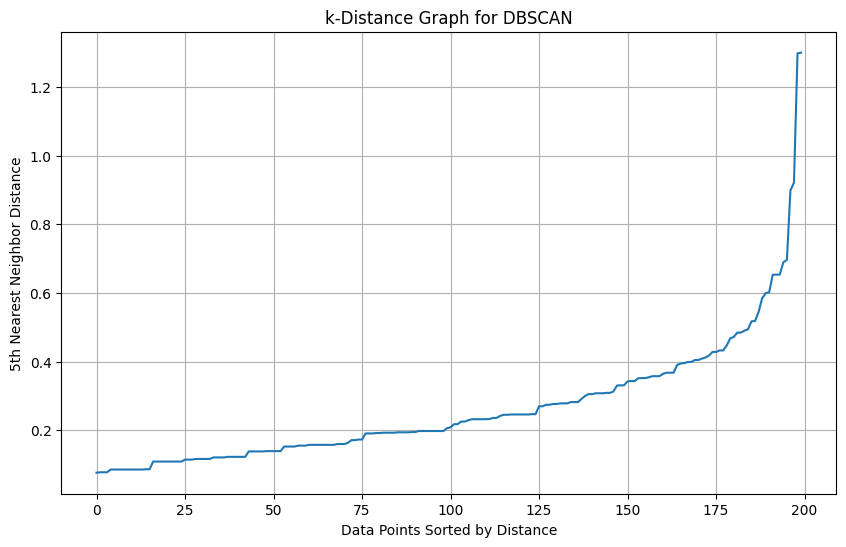

In [4]:

# Task 3: Hyperparameter Selection via k-Distance Graph

# Set min_samples
min_samples = 5

# Compute nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort the distances to the kth nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

# Plot k-distance graph
plt.figure(figsize=(10, 6))
plt.plot(k_distances)
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("k-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

Cluster Labels:
[ 2  0  1  0  2  0  1 -1  1  0 -1 -1 -1  0  1  0  2  0  2 -1  2  0  1  0
 -1 -1  2 -1  2 -1 -1  0 -1 -1 -1 -1 -1  0 -1  0  3 -1  3  3  3  3  3  3
  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3
  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3
  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3
  3  3  3  4  3  4  3  4  5  4  5  4  3  4  5  4  5  4  5  4  5  4  3  4
  5  4  3  4  5  4  5  4  5  4  5  4  5  4  5  4  3  4  5  4  6  4  6  4
  6 -1  6  4  6  4  6  4  6  4  6  4 -1  4  6  4 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]

Number of Clusters: 7
Number of Noise Points: 35


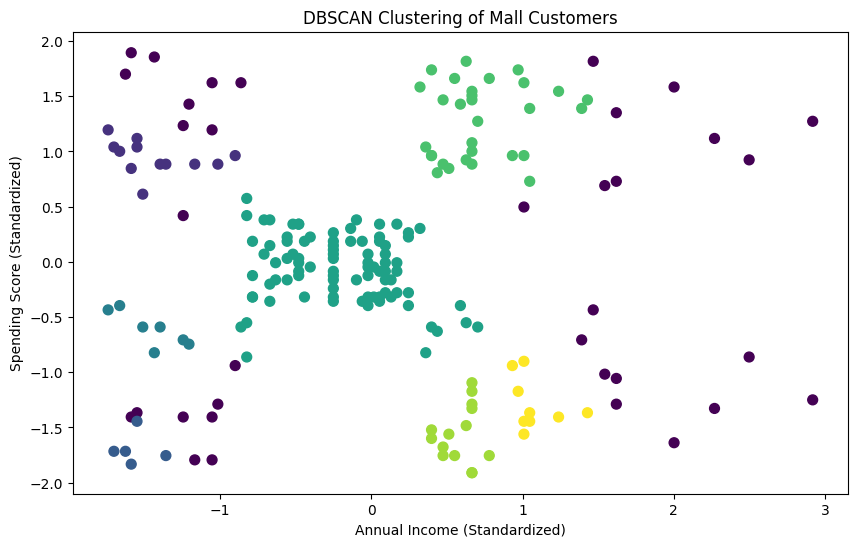

In [5]:

# Task 4: Apply DBSCAN Clustering

# Set DBSCAN parameters
eps = 0.3
min_samples = 5

# Apply DBSCAN clustering
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels = dbscan.fit_predict(X_scaled)

# Display cluster labels
print("Cluster Labels:")
print(labels)

# Count the number of clusters and noise points
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

# Visualize the clusters
plt.figure(figsize=(10, 6))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap='viridis',
    s=50
)

plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.title("DBSCAN Clustering of Mall Customers")
plt.show()


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [6]:

# Task 5: Evaluate Clustering

# Count the number of clusters
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

# Count the number of noise points
n_noise = list(labels).count(-1)

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

# Calculate Silhouette Score
if 2 <= n_clusters < len(X_scaled):
    score = silhouette_score(X_scaled, labels)
    print("Silhouette Score:", score)
else:
    print("Silhouette Score cannot be calculated.")

# Display cluster distribution
unique_labels, counts = np.unique(labels, return_counts=True)

print("\nCluster Distribution:")
for cluster, count in zip(unique_labels, counts):
    if cluster == -1:
        print("Noise Points:", count)
    else:
        print(f"Cluster {cluster}: {count} customers")


Number of Clusters: 7
Number of Noise Points: 35
Silhouette Score: 0.31614121976731185

Cluster Distribution:
Noise Points: 35
Cluster 0: 12 customers
Cluster 1: 5 customers
Cluster 2: 7 customers
Cluster 3: 88 customers
Cluster 4: 30 customers
Cluster 5: 14 customers
Cluster 6: 9 customers


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [7]:

# Task 6: Add Cluster Labels and Calculate Cluster Statistics

# Add cluster labels to the original dataset
df['Cluster'] = labels

# Display first five rows
print("Dataset with Cluster Labels:")
print(df.head())

# Calculate statistics for each cluster
print("\nCluster Statistics:")

cluster_stats = df[df['Cluster'] != -1].groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean()

print(cluster_stats)

# Display number of customers in each cluster
print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Display noise points
noise_points = df[df['Cluster'] == -1]

print("\nNumber of Noise Points:", len(noise_points))


Dataset with Cluster Labels:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        2  
1        0  
2        1  
3        0  
4        2  

Cluster Statistics:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 23.166667               74.583333
1                 19.600000                6.600000
2                 22.428571               34.428571
3                 55.227273               48.579545
4                 79.533333               83.133333
5                 75.928571               10.071429
6          

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.